In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import sys

print(sys.executable)

e:\work\python\project\bike-rental-prediction\.venv\Scripts\python.exe


In [7]:
df = pd.read_csv("../data/hour.csv")
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [8]:
corr_df = df.drop(columns=["instant", "registered", "casual"])
corr_matrix = corr_df.corr(numeric_only=True)

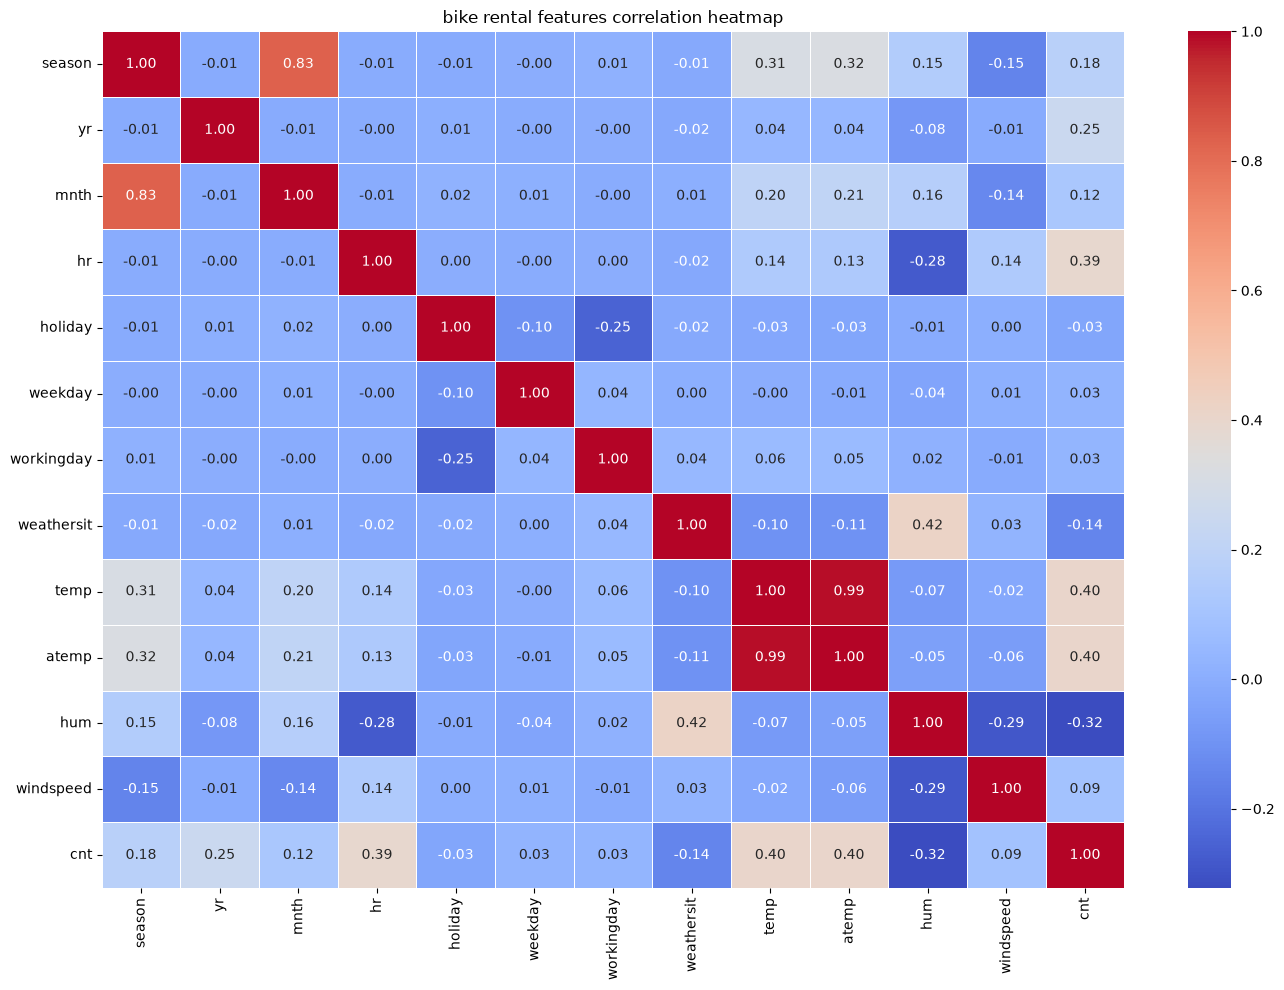

In [9]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)

plt.title("bike rental features correlation heatmap")
plt.tight_layout()
plt.show()

The heatmap reveals strong correlations between temp and atemp (0.99) and season and mnth (0.83), while temp has the strongest positive correlation with rental demand and hum has the strongest negative correlation, helping identify redundant and potentially useful features for ML.

Text(0, 0.5, 'frequency')

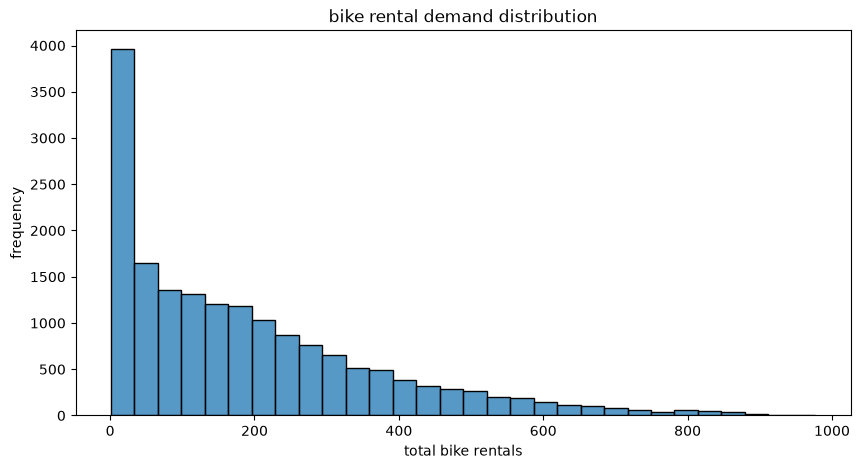

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data = df, x="cnt",
    bins=30,
)

plt.title("bike rental demand distribution")
plt.xlabel("total bike rentals")
plt.ylabel("frequency")

The rental demand distribution is right-skewed, indicating that low rental demand occurred more frequently than high rental demand.

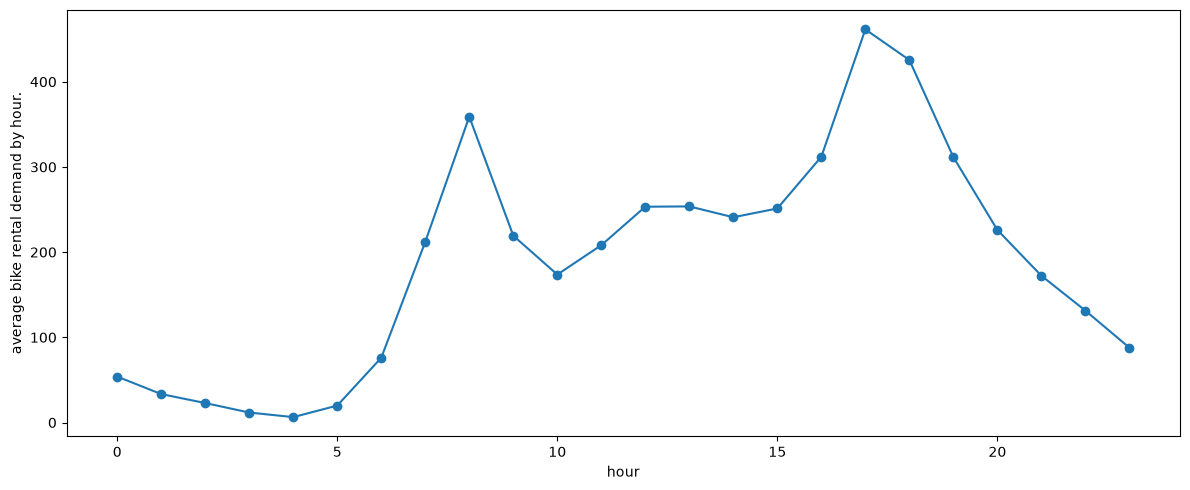

In [16]:
hourly_average = df.groupby("hr")["cnt"].mean()
x = hourly_average.index
y = hourly_average.values

plt.figure(figsize=(12, 5))
plt.plot(x, y, marker="o")

plt.xlabel("hour")
plt.ylabel("average bike rental demand by hour.")

plt.tight_layout()
plt.show()

In [ ]:
weather_counts = df["weathersit"].value_counts()

weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

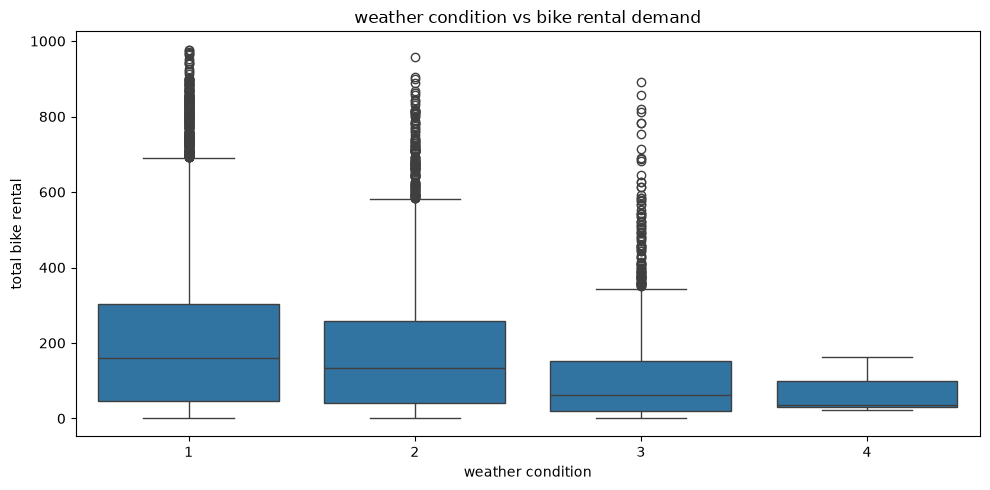

In [21]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data = df,
    x = "weathersit",
    y = "cnt"
)

plt.title("weather condition vs bike rental demand")
plt.xlabel("weather condition")
plt.ylabel("total bike rental")
plt.tight_layout()
plt.show()